In [11]:
import yfinance as yf
import pandas as pd
import numpy as np
from scipy.optimize import minimize
import matplotlib.pyplot as plt

In [8]:
# 1. Define your 15 stock tickers and the market benchmark (e.g., S&P 500 is '^GSPC')
tickers = [
    'AAPL',
    'MSFT',
    'GOOGL',
    'AMZN',
    'NVDA',
    'META',
    'TSLA',
    'JPM',
    'V',
    'JNJ',
    'WMT',
    'PG',
    'MA',
    'UNH',
    'HD',
]
market_ticker = '^GSPC'  # S&P 500 as the market portfolio

# Combine all into one list
all_tickers = tickers + [market_ticker]

# 2. Download historical adjusted close prices for the last 5 years
print('Downloading historical data...')
data = yf.download(all_tickers, start='2021-01-01', end='2026-01-01')[
    'Close'
]

# 3. Rename the market column to 'Market' for easy referencing later
data = data.rename(columns={market_ticker: 'Market'})

# 4. Clean missing values and drop incomplete rows
data = data.dropna()

# 5. Save directly to your desktop path so your assignment code can read it
output_path = r'C:\Users\User\OneDrive\Desktop\I am python\15stocks_price.csv'
data.to_csv(output_path)

print(f'Data successfully downloaded and saved to:\n{output_path}')
print(data.head())

[*********************100%***********************]  15 of 16 completed
[*********************100%***********************]  15 of 16 completed

Data successfully downloaded and saved to:
C:\Users\User\OneDrive\Desktop\I am python\15stocks_price.csv
Ticker            AAPL        AMZN      GOOGL          HD         JNJ  \
Date                                                                    
2021-01-04  125.632484  159.331497  85.492981  228.691544  133.628311   
2021-01-05  127.185776  160.925507  86.182411  230.537170  135.199402   
2021-01-06  122.904526  156.919006  85.332001  231.854340  136.471680   
2021-01-07  127.098427  158.108002  87.880753  230.719254  136.932739   
2021-01-08  128.195465  159.134995  89.044182  233.171509  136.650986   

Ticker             JPM          MA        META        MSFT       NVDA  \
Date                                                                    
2021-01-04  108.459412  339.494720  266.388611  207.565369  13.046195   
2021-01-05  109.049606  335.563721  268.399353  207.765610  13.335952   
2021-01-06  114.170113  335.689178  260.811981  202.378418  12.549760   
2021-01-07  117.91

In [9]:
# STEP 1: LOAD & PREPARE DATA
# ==========================================
# Update the path to match your CSV file containing 15 stocks and the 'Market' column
file_path = r'C:\Users\User\OneDrive\Desktop\I am python\15stocks_price.csv'
df = pd.read_csv(file_path, parse_dates=True, index_col=0)

# Clean and ensure all data is numeric
df = df.apply(pd.to_numeric, errors='coerce').dropna()
df = df.sort_index()

# Separate stock assets from the market portfolio ('Market')
market_col = 'Market'
stock_cols = [col for col in df.columns if col != market_col]

stock_df = df[stock_cols]
market_series = df[market_col]

# Calculate daily returns, annualized expected returns, and covariance matrix (252 trading days)
stock_returns = stock_df.pct_change().dropna()
market_returns = market_series.pct_change().dropna()

mean_returns = stock_returns.mean() * 252  # Annualized expected return vector
vcv = stock_returns.cov() * 252  # Annualized Variance-Covariance matrix

mkt_exp_return = market_returns.mean() * 252
mkt_annual_risk = market_returns.std() * np.sqrt(252)

num_assets = len(stock_cols)

# ==========================================
# STEP 2-4: INITIAL PORTFOLIO METRICS
# ==========================================
# 1. Create a vector of weights which sum up to 1 (Equal weights)
init_weights = np.array([1 / num_assets] * num_assets)


def get_portfolio_metrics(weights):
  p_return = np.sum(mean_returns * weights)
  p_variance = np.dot(weights.T, np.dot(vcv, weights))
  p_risk = np.sqrt(p_variance)
  return p_return, p_risk


init_ret, init_risk = get_portfolio_metrics(init_weights)

print('========================================')
print('INITIAL PORTFOLIO & MARKET BENCHMARK')
print('========================================')
print(f'Initial Portfolio Annualized Return: {init_ret*100:.2f}%')
print(f'Initial Portfolio Annualized Risk:   {init_risk*100:.2f}%')
print(f'Market Annualized Expected Return:   {mkt_exp_return*100:.2f}%')
print(f'Market Annualized Risk (Std Dev):    {mkt_annual_risk*100:.2f}%\n')

# Common optimizer configurations
bounds = tuple((0, 1) for _ in range(num_assets))  # Weights between 0 and 1
sum_constraint = {'type': 'eq', 'fun': lambda x: np.sum(x) - 1}


# ==========================================
# QUESTION 1: Target Return = Market Return
# ==========================================
def objective_var(weights):
  return np.dot(weights.T, np.dot(vcv, weights))


ret_constraint = {
    'type': 'eq',
    'fun': lambda x: np.sum(mean_returns * x) - mkt_exp_return,
}

res_q1 = minimize(
    objective_var,
    init_weights,
    method='SLSQP',
    bounds=bounds,
    constraints=[sum_constraint, ret_constraint],
)
q1_ret, q1_risk = get_portfolio_metrics(res_q1.x)

print('========================================')
print('QUESTION 1: Target Return = Market Return')
print('========================================')
print(f'Optimized Portfolio Risk: {q1_risk*100:.2f}%')
print(
    'Comparison: Compare this risk value against the market risk ('
    f'{mkt_annual_risk*100:.2f}%) and initial portfolio risk ('
    f'{init_risk*100:.2f}%).\n'
)


# ==========================================
# QUESTION 2: Target Risk = Market Risk
# ==========================================
def objective_neg_return(weights):
  return -np.sum(mean_returns * weights)


risk_constraint = {
    'type': 'eq',
    'fun': lambda x: np.sqrt(np.dot(x.T, np.dot(vcv, x))) - mkt_annual_risk,
}

res_q2 = minimize(
    objective_neg_return,
    init_weights,
    method='SLSQP',
    bounds=bounds,
    constraints=[sum_constraint, risk_constraint],
)
q2_ret, q2_risk = get_portfolio_metrics(res_q2.x)

print('========================================')
print('QUESTION 2: Target Risk = Market Risk')
print('========================================')
print(f'Optimized Portfolio Expected Return: {q2_ret*100:.2f}%')
print(f'Market Return Benchmark:             {mkt_exp_return*100:.2f}%\n')


# ==========================================
# QUESTION 3: Minimum Variance Portfolio
# ==========================================
def objective_risk(weights):
  return np.sqrt(np.dot(weights.T, np.dot(vcv, weights)))


res_q3 = minimize(
    objective_risk,
    init_weights,
    method='SLSQP',
    bounds=bounds,
    constraints=[sum_constraint],
)
q3_ret, q3_risk = get_portfolio_metrics(res_q3.x)

print('========================================')
print('QUESTION 3: Minimum Variance Portfolio (MVP)')
print('========================================')
print(f'Minimum Variance Portfolio Return: {q3_ret*100:.2f}%')
print(f'Minimum Variance Portfolio Risk:   {q3_risk*100:.2f}%\n')

INITIAL PORTFOLIO & MARKET BENCHMARK
Initial Portfolio Annualized Return: 20.69%
Initial Portfolio Annualized Risk:   19.00%
Market Annualized Expected Return:   13.80%
Market Annualized Risk (Std Dev):    16.96%

QUESTION 1: Target Return = Market Return
Optimized Portfolio Risk: 12.51%
Comparison: Compare this risk value against the market risk (16.96%) and initial portfolio risk (19.00%).

QUESTION 2: Target Risk = Market Risk
Optimized Portfolio Expected Return: 28.11%
Market Return Benchmark:             13.80%

QUESTION 3: Minimum Variance Portfolio (MVP)
Minimum Variance Portfolio Return: 13.15%
Minimum Variance Portfolio Risk:   12.51%



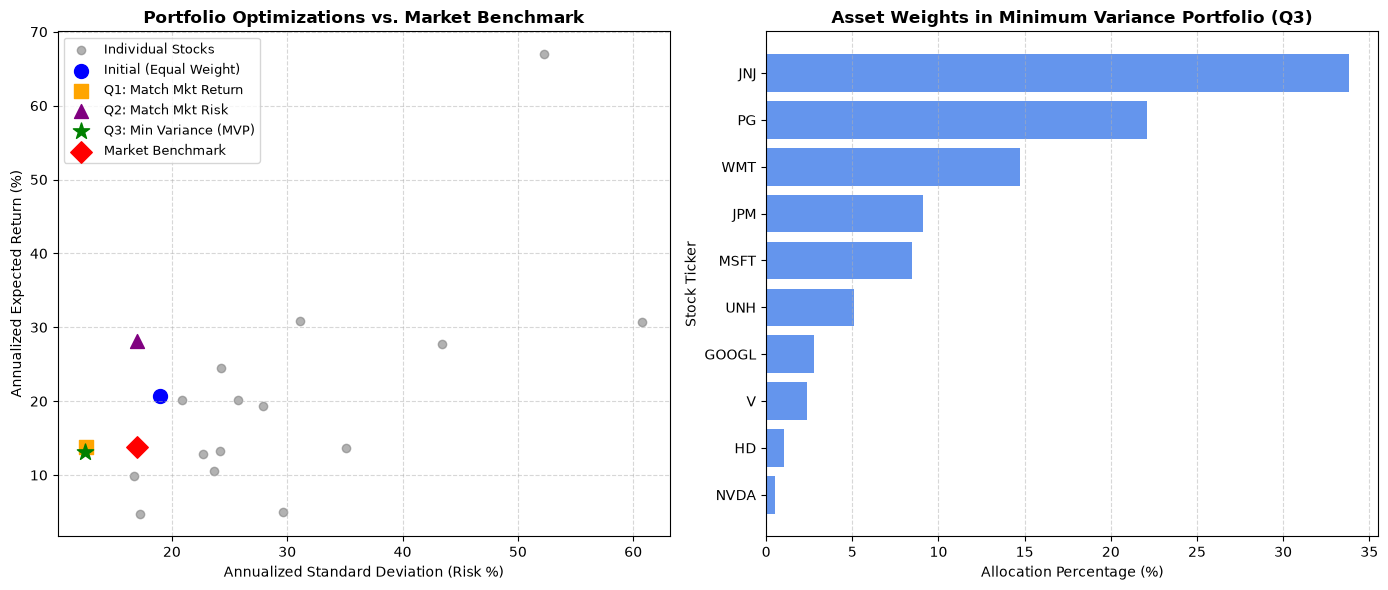

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize

# ==========================================
# STEP 1: LOAD & PREPARE DATA
# ==========================================
file_path = r'C:\Users\User\OneDrive\Desktop\I am python\15stocks_price.csv'
df = pd.read_csv(file_path, parse_dates=True, index_col=0)

# Clean and ensure numeric data
df = df.apply(pd.to_numeric, errors='coerce').dropna()
df = df.sort_index()

market_col = 'Market'
stock_cols = [col for col in df.columns if col != market_col]

stock_df = df[stock_cols]
market_series = df[market_col]

stock_returns = stock_df.pct_change().dropna()
market_returns = market_series.pct_change().dropna()

mean_returns = stock_returns.mean() * 252  # Annualized expected return
vcv = stock_returns.cov() * 252  # Annualized covariance matrix

mkt_exp_return = market_returns.mean() * 252
mkt_annual_risk = market_returns.std() * np.sqrt(252)

num_assets = len(stock_cols)

# ==========================================
# STEP 2-4: INITIAL PORTFOLIO METRICS
# ==========================================
init_weights = np.array([1 / num_assets] * num_assets)


def get_portfolio_metrics(weights):
  p_return = np.sum(mean_returns * weights)
  p_variance = np.dot(weights.T, np.dot(vcv, weights))
  p_risk = np.sqrt(p_variance)
  return p_return, p_risk


init_ret, init_risk = get_portfolio_metrics(init_weights)

# ==========================================
# OPTIMIZATIONS (Q1, Q2, Q3)
# ==========================================
bounds = tuple((0, 1) for _ in range(num_assets))
sum_constraint = {'type': 'eq', 'fun': lambda x: np.sum(x) - 1}


# Q1: Target Return = Market Return
def objective_var(weights):
  return np.dot(weights.T, np.dot(vcv, weights))


ret_constraint = {
    'type': 'eq',
    'fun': lambda x: np.sum(mean_returns * x) - mkt_exp_return,
}
res_q1 = minimize(
    objective_var,
    init_weights,
    method='SLSQP',
    bounds=bounds,
    constraints=[sum_constraint, ret_constraint],
)
q1_ret, q1_risk = get_portfolio_metrics(res_q1.x)


# Q2: Target Risk = Market Risk
def objective_neg_return(weights):
  return -np.sum(mean_returns * weights)


risk_constraint = {
    'type': 'eq',
    'fun': lambda x: np.sqrt(np.dot(x.T, np.dot(vcv, x))) - mkt_annual_risk,
}
res_q2 = minimize(
    objective_neg_return,
    init_weights,
    method='SLSQP',
    bounds=bounds,
    constraints=[sum_constraint, risk_constraint],
)
q2_ret, q2_risk = get_portfolio_metrics(res_q2.x)


# Q3: Minimum Variance Portfolio
def objective_risk(weights):
  return np.sqrt(np.dot(weights.T, np.dot(vcv, weights)))


res_q3 = minimize(
    objective_risk,
    init_weights,
    method='SLSQP',
    bounds=bounds,
    constraints=[sum_constraint],
)
q3_ret, q3_risk = get_portfolio_metrics(res_q3.x)
mvp_weights = res_q3.x


# ==========================================
# MATPLOTLIB VISUALIZATION DASHBOARD
# ==========================================
fig = plt.figure(figsize=(14, 6))

# --- Plot 1: Risk vs Return Optimization Overview ---
ax1 = fig.add_subplot(1, 2, 1)

# Scatter plot of individual stocks
stock_risks = stock_returns.std() * np.sqrt(252)
ax1.scatter(
    stock_risks * 100,
    mean_returns * 100,
    color='gray',
    alpha=0.6,
    label='Individual Stocks',
)

# Key portfolios
ax1.scatter(
    init_risk * 100,
    init_ret * 100,
    color='blue',
    marker='o',
    s=100,
    label='Initial (Equal Weight)',
)
ax1.scatter(
    q1_risk * 100,
    q1_ret * 100,
    color='orange',
    marker='s',
    s=100,
    label='Q1: Match Mkt Return',
)
ax1.scatter(
    q2_risk * 100,
    q2_ret * 100,
    color='purple',
    marker='^',
    s=100,
    label='Q2: Match Mkt Risk',
)
ax1.scatter(
    q3_risk * 100,
    q3_ret * 100,
    color='green',
    marker='*',
    s=150,
    label='Q3: Min Variance (MVP)',
)
ax1.scatter(
    mkt_annual_risk * 100,
    mkt_exp_return * 100,
    color='red',
    marker='D',
    s=120,
    label='Market Benchmark',
)

ax1.set_title(
    'Portfolio Optimizations vs. Market Benchmark',
    fontsize=12,
    fontweight='bold',
)
ax1.set_xlabel('Annualized Standard Deviation (Risk %)', fontsize=10)
ax1.set_ylabel('Annualized Expected Return (%)', fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper left', fontsize=9)

# --- Plot 2: Minimum Variance Portfolio Asset Allocation ---
ax2 = fig.add_subplot(1, 2, 2)

# Filter out zero or near-zero weights for clean visualization
weights_series = pd.Series(mvp_weights * 100, index=stock_cols)
weights_series = weights_series[weights_series > 0.01].sort_values(
    ascending=True
)

ax2.barh(weights_series.index, weights_series.values, color='cornflowerblue')
ax2.set_title(
    'Asset Weights in Minimum Variance Portfolio (Q3)',
    fontsize=12,
    fontweight='bold',
)
ax2.set_xlabel('Allocation Percentage (%)', fontsize=10)
ax2.set_ylabel('Stock Ticker', fontsize=10)
ax2.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()